In [1]:
import pandas as pd
import numpy as np

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report,
    confusion_matrix
)

In [2]:
df = pd.read_csv(
    "WA_Fn-UseC_-Telco-Customer-Churn.csv"
)

print("Dataset shape:", df.shape)
display(df.head())

Dataset shape: (7043, 21)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [3]:
df = df.drop_duplicates().copy()

df["TotalCharges"] = pd.to_numeric(
    df["TotalCharges"], errors="coerce"
)

df["Churn"] = df["Churn"].map({"No": 0, "Yes": 1})

X = df.drop(columns=["Churn", "customerID"])
y = df["Churn"]

print("Features:", X.shape)
print("Target:", y.shape)
print("\nTarget distribution:")
print(y.value_counts())

Features: (7043, 19)
Target: (7043,)

Target distribution:
Churn
0    5174
1    1869
Name: count, dtype: int64


In [4]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training records:", X_train.shape[0])
print("Testing records:", X_test.shape[0])

Training records: 5634
Testing records: 1409


In [5]:
numeric_features = X.select_dtypes(
    include=["number"]
).columns.tolist()

categorical_features = X.select_dtypes(
    include=["object", "category", "bool"]
).columns.tolist()

numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer([
    ("num", numeric_pipeline, numeric_features),
    ("cat", categorical_pipeline, categorical_features)
])

model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(
        max_iter=2000,
        class_weight="balanced",
        random_state=42
    ))
])

model.fit(X_train, y_train)

print("Model training completed successfully!")

C:\Users\alimu\AppData\Local\Temp\ipykernel_6196\3672045340.py:5: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_features = X.select_dtypes(


Model training completed successfully!


In [6]:
y_pred = model.predict(X_test)
y_prob = model.predict_proba(X_test)[:, 1]

print("Accuracy:", round(accuracy_score(y_test, y_pred), 4))
print("Precision:", round(precision_score(y_test, y_pred), 4))
print("Recall:", round(recall_score(y_test, y_pred), 4))
print("F1-score:", round(f1_score(y_test, y_pred), 4))
print("ROC-AUC:", round(roc_auc_score(y_test, y_prob), 4))

print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred,
    target_names=["No Churn", "Churn"]
))

print("Confusion Matrix:")
print(confusion_matrix(y_test, y_pred))

Accuracy: 0.7381
Precision: 0.5043
Recall: 0.7834
F1-score: 0.6136
ROC-AUC: 0.8413

Classification Report:
              precision    recall  f1-score   support

    No Churn       0.90      0.72      0.80      1035
       Churn       0.50      0.78      0.61       374

    accuracy                           0.74      1409
   macro avg       0.70      0.75      0.71      1409
weighted avg       0.80      0.74      0.75      1409

Confusion Matrix:
[[747 288]
 [ 81 293]]


In [7]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import Pipeline

rf_model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", RandomForestClassifier(
        n_estimators=300,
        class_weight="balanced",
        random_state=42,
        n_jobs=-1
    ))
])

rf_model.fit(X_train, y_train)

print("Random Forest training completed!")

Random Forest training completed!


In [8]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report,
    confusion_matrix
)

rf_pred = rf_model.predict(X_test)
rf_prob = rf_model.predict_proba(X_test)[:, 1]

rf_results = {
    "Accuracy": accuracy_score(y_test, rf_pred),
    "Precision": precision_score(y_test, rf_pred),
    "Recall": recall_score(y_test, rf_pred),
    "F1-score": f1_score(y_test, rf_pred),
    "ROC-AUC": roc_auc_score(y_test, rf_prob)
}

for metric, score in rf_results.items():
    print(f"{metric}: {score:.4f}")

print("\nClassification Report:")
print(classification_report(
    y_test,
    rf_pred,
    target_names=["No Churn", "Churn"]
))

print("Confusion Matrix:")
print(confusion_matrix(y_test, rf_pred))

Accuracy: 0.7658
Precision: 0.5521
Recall: 0.6230
F1-score: 0.5854
ROC-AUC: 0.8218

Classification Report:
              precision    recall  f1-score   support

    No Churn       0.86      0.82      0.84      1035
       Churn       0.55      0.62      0.59       374

    accuracy                           0.77      1409
   macro avg       0.70      0.72      0.71      1409
weighted avg       0.78      0.77      0.77      1409

Confusion Matrix:
[[846 189]
 [141 233]]


In [9]:
comparison = pd.DataFrame({
    "Metric": list(rf_results.keys()),
    "Logistic Regression": [
        accuracy_score(y_test, model.predict(X_test)),
        precision_score(y_test, model.predict(X_test)),
        recall_score(y_test, model.predict(X_test)),
        f1_score(y_test, model.predict(X_test)),
        roc_auc_score(
            y_test, model.predict_proba(X_test)[:, 1]
        )
    ],
    "Random Forest": list(rf_results.values())
})

display(comparison.round(4))

,Metric,Logistic Regression,Random Forest
0,Accuracy,0.7381,0.7658
1,Precision,0.5043,0.5521
2,Recall,0.7834,0.6230
3,F1-score,0.6136,0.5854
4,ROC-AUC,0.8413,0.8218


In [10]:
%pip install xgboost

Note: you may need to restart the kernel to use updated packages.


In [11]:
from xgboost import XGBClassifier
from sklearn.pipeline import Pipeline

xgb_model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", XGBClassifier(
        n_estimators=300,
        max_depth=4,
        learning_rate=0.05,
        subsample=0.8,
        colsample_bytree=0.8,
        eval_metric="logloss",
        random_state=42,
        n_jobs=-1
    ))
])

xgb_model.fit(X_train, y_train)

print("XGBoost training completed!")

XGBoost training completed!


In [12]:
xgb_pred = xgb_model.predict(X_test)
xgb_prob = xgb_model.predict_proba(X_test)[:, 1]

xgb_results = {
    "Accuracy": accuracy_score(y_test, xgb_pred),
    "Precision": precision_score(y_test, xgb_pred),
    "Recall": recall_score(y_test, xgb_pred),
    "F1-score": f1_score(y_test, xgb_pred),
    "ROC-AUC": roc_auc_score(y_test, xgb_prob)
}

for metric, score in xgb_results.items():
    print(f"{metric}: {score:.4f}")

print("\nClassification Report:")
print(classification_report(
    y_test,
    xgb_pred,
    target_names=["No Churn", "Churn"]
))

print("Confusion Matrix:")
print(confusion_matrix(y_test, xgb_pred))

Accuracy: 0.7984
Precision: 0.6510
Recall: 0.5187
F1-score: 0.5774
ROC-AUC: 0.8427

Classification Report:
              precision    recall  f1-score   support

    No Churn       0.84      0.90      0.87      1035
       Churn       0.65      0.52      0.58       374

    accuracy                           0.80      1409
   macro avg       0.74      0.71      0.72      1409
weighted avg       0.79      0.80      0.79      1409

Confusion Matrix:
[[931 104]
 [180 194]]


In [13]:
comparison = pd.DataFrame({
    "Metric": [
        "Accuracy", "Precision", "Recall", "F1-score", "ROC-AUC"
    ],
    "Logistic Regression": [
        0.7381, 0.5043, 0.7834, 0.6136, 0.8413
    ],
    "Random Forest": [
        0.7658, 0.5521, 0.6230, 0.5854, 0.8218
    ],
    "XGBoost": [
        xgb_results["Accuracy"],
        xgb_results["Precision"],
        xgb_results["Recall"],
        xgb_results["F1-score"],
        xgb_results["ROC-AUC"]
    ]
})

display(comparison.round(4))

,Metric,Logistic Regression,Random Forest,XGBoost
0,Accuracy,0.7381,0.7658,0.7984
1,Precision,0.5043,0.5521,0.6510
2,Recall,0.7834,0.6230,0.5187
3,F1-score,0.6136,0.5854,0.5774
4,ROC-AUC,0.8413,0.8218,0.8427


In [14]:
from sklearn.metrics import precision_score, recall_score, f1_score

xgb_prob = xgb_model.predict_proba(X_test)[:, 1]

threshold_results = []

for threshold in [0.20, 0.25, 0.30, 0.35, 0.40, 0.45, 0.50]:
    predictions = (xgb_prob >= threshold).astype(int)

    threshold_results.append({
        "Threshold": threshold,
        "Precision": precision_score(
            y_test, predictions, zero_division=0
        ),
        "Recall": recall_score(y_test, predictions),
        "F1-score": f1_score(y_test, predictions)
    })

threshold_df = pd.DataFrame(threshold_results)

display(threshold_df.round(4))

,Threshold,Precision,Recall,F1-score
0,0.20,0.4891,0.8369,0.6174
1,0.25,0.5128,0.8048,0.6264
2,0.30,0.5321,0.7540,0.6239
3,0.35,0.5506,0.6979,0.6156
4,0.40,0.5861,0.6551,0.6187
5,0.45,0.6173,0.5909,0.6038
6,0.50,0.6510,0.5187,0.5774


In [15]:
from sklearn.metrics import (
    confusion_matrix,
    classification_report,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)

best_threshold = 0.25

xgb_prob = xgb_model.predict_proba(X_test)[:, 1]
xgb_tuned_pred = (xgb_prob >= best_threshold).astype(int)

print("Threshold:", best_threshold)
print("Accuracy:", round(
    accuracy_score(y_test, xgb_tuned_pred), 4
))
print("Precision:", round(
    precision_score(y_test, xgb_tuned_pred), 4
))
print("Recall:", round(
    recall_score(y_test, xgb_tuned_pred), 4
))
print("F1-score:", round(
    f1_score(y_test, xgb_tuned_pred), 4
))
print("ROC-AUC:", round(
    roc_auc_score(y_test, xgb_prob), 4
))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, xgb_tuned_pred))

print("\nClassification Report:")
print(classification_report(
    y_test,
    xgb_tuned_pred,
    target_names=["No Churn", "Churn"]
))

Threshold: 0.25
Accuracy: 0.7452
Precision: 0.5128
Recall: 0.8048
F1-score: 0.6264
ROC-AUC: 0.8427

Confusion Matrix:
[[749 286]
 [ 73 301]]

Classification Report:
              precision    recall  f1-score   support

    No Churn       0.91      0.72      0.81      1035
       Churn       0.51      0.80      0.63       374

    accuracy                           0.75      1409
   macro avg       0.71      0.76      0.72      1409
weighted avg       0.81      0.75      0.76      1409



In [16]:
import pandas as pd
import matplotlib.pyplot as plt

# Preprocessing ke baad feature names
feature_names = (
    xgb_model
    .named_steps["preprocessor"]
    .get_feature_names_out()
)

# XGBoost feature importance
importances = (
    xgb_model
    .named_steps["classifier"]
    .feature_importances_
)

feature_importance = pd.DataFrame({
    "Feature": feature_names,
    "Importance": importances
})

feature_importance = feature_importance.sort_values(
    by="Importance",
    ascending=False
)

display(feature_importance.head(15))

,Feature,Importance
36,cat__Contract_Month-to-month,0.368104
16,cat__InternetService_Fiber optic,0.107298
18,cat__OnlineSecurity_No,0.054342
27,cat__TechSupport_No,0.049986
15,cat__InternetService_DSL,0.038270
38,cat__Contract_Two year,0.032237
17,cat__InternetService_No,0.031362
43,cat__PaymentMethod_Electronic check,0.020842
1,num__tenure,0.018279
35,cat__StreamingMovies_Yes,0.015828


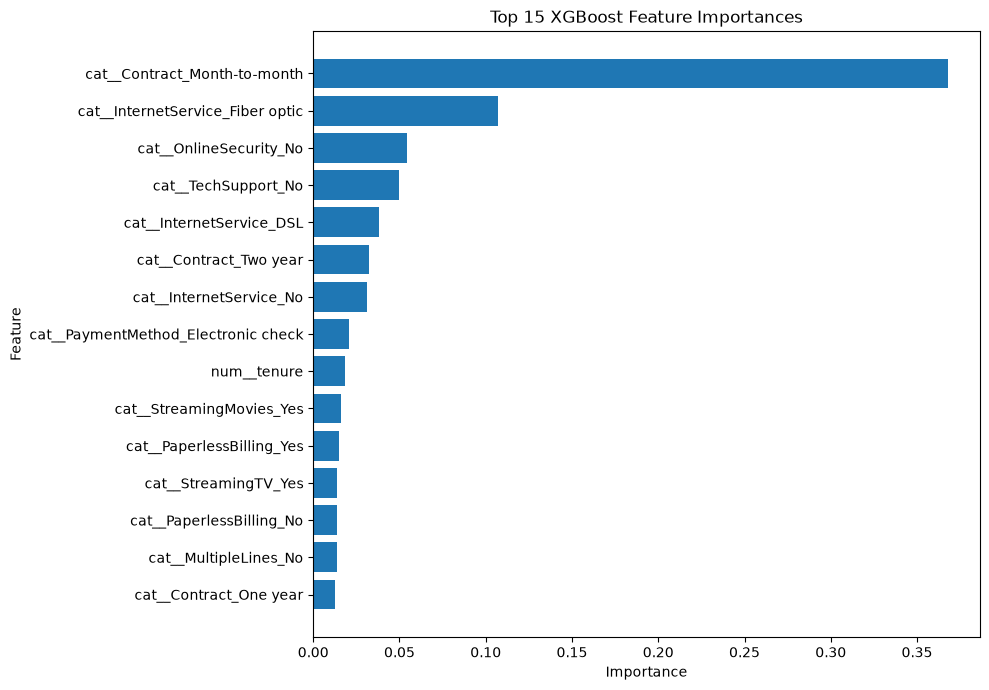

In [17]:
top_features = feature_importance.head(15).sort_values(
    "Importance",
    ascending=True
)

plt.figure(figsize=(10, 7))

plt.barh(
    top_features["Feature"],
    top_features["Importance"]
)

plt.title("Top 15 XGBoost Feature Importances")
plt.xlabel("Importance")
plt.ylabel("Feature")
plt.tight_layout()
plt.show()

In [18]:
import os
import joblib

os.makedirs("models", exist_ok=True)

model_artifact = {
    "model": xgb_model,
    "threshold": 0.25,
    "features": X.columns.tolist()
}

joblib.dump(
    model_artifact,
    "models/customer_churn_xgboost.joblib"
)

print("Model saved successfully!")

Model saved successfully!


In [19]:
loaded_artifact = joblib.load(
    "models/customer_churn_xgboost.joblib"
)

loaded_model = loaded_artifact["model"]
threshold = loaded_artifact["threshold"]

sample_probabilities = loaded_model.predict_proba(
    X_test.iloc[:5]
)[:, 1]

sample_predictions = (
    sample_probabilities >= threshold
).astype(int)

results = pd.DataFrame({
    "Actual Churn": y_test.iloc[:5].values,
    "Churn Probability": sample_probabilities.round(4),
    "Predicted Churn": sample_predictions
})

display(results)

,Actual Churn,Churn Probability,Predicted Churn
0,0,0.0115,0
1,0,0.9031,1
2,0,0.0754,0
3,0,0.3175,1
4,0,0.0066,0


In [20]:
%pip install shap

Note: you may need to restart the kernel to use updated packages.


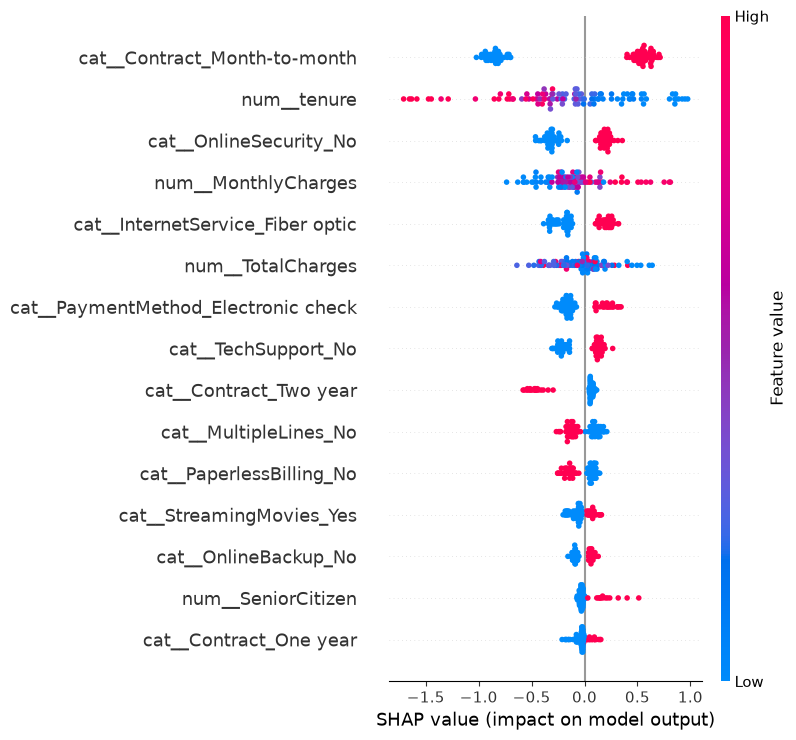

In [21]:
import shap

# Preprocessing ke baad transformed data
preprocessor = loaded_model.named_steps["preprocessor"]
xgb_classifier = loaded_model.named_steps["classifier"]

X_sample = X_test.iloc[:100].copy()
X_transformed = preprocessor.transform(X_sample)

feature_names = preprocessor.get_feature_names_out()

# SHAP explainer
explainer = shap.TreeExplainer(xgb_classifier)

shap_values = explainer.shap_values(X_transformed)

# Global feature importance
shap.summary_plot(
    shap_values,
    X_transformed,
    feature_names=feature_names,
    max_display=15
)

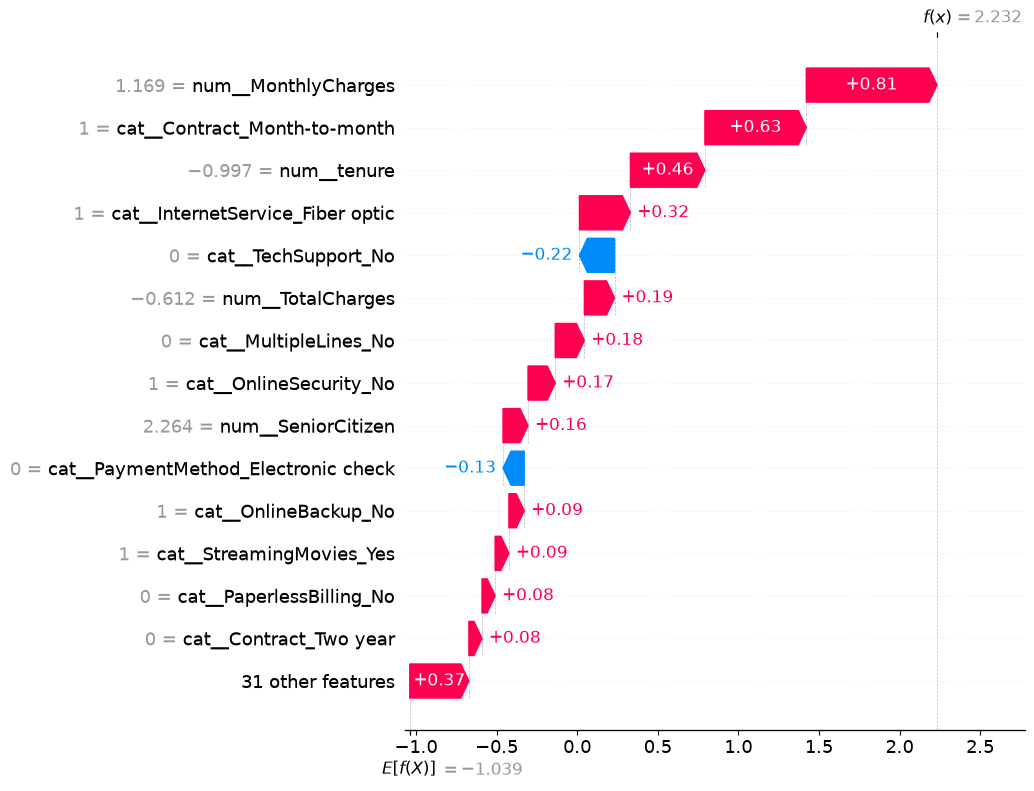

In [22]:
import numpy as np
import pandas as pd
import shap
import matplotlib.pyplot as plt

# Test set ka ek customer select karein
customer = X_test.iloc[[1]]

# Trained preprocessing apply karein
preprocessor = loaded_model.named_steps["preprocessor"]
classifier = loaded_model.named_steps["classifier"]

customer_transformed = preprocessor.transform(customer)

feature_names = preprocessor.get_feature_names_out()

# SHAP explanation
explainer = shap.TreeExplainer(classifier)

customer_shap = explainer.shap_values(
    customer_transformed
)

# Customer ki feature values
customer_features = pd.DataFrame(
    customer_transformed.toarray()
    if hasattr(customer_transformed, "toarray")
    else customer_transformed,
    columns=feature_names
)

# Waterfall plot
shap_explanation = shap.Explanation(
    values=customer_shap[0],
    base_values=explainer.expected_value,
    data=customer_features.iloc[0].values,
    feature_names=feature_names
)

shap.plots.waterfall(shap_explanation, max_display=15)

In [23]:
customer = X_test.iloc[[1]]

probability = loaded_model.predict_proba(customer)[0, 1]
prediction = int(probability >= threshold)

print(f"Churn Probability: {probability:.2%}")
print(f"Threshold: {threshold:.2f}")
print(
    "Prediction:",
    "Churn Risk" if prediction == 1 else "Low Churn Risk"
)

Churn Probability: 90.31%
Threshold: 0.25
Prediction: Churn Risk
